In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

# Automatically locate the project folder
# Works when Jupyter runs from the notebooks/ directory

project_root = Path.cwd()

if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

print("Project root:", project_root)

# Dataset location
data_path = project_root / "data" / "raw" / "online_retail_II.xlsx"

# Check that the dataset exists
print("Project root:", project_root)
print("Dataset exists:", data_path.exists())

# Read all Excel sheets
excel_file = pd.ExcelFile(data_path)

df = pd.concat(
    [
        pd.read_excel(data_path, sheet_name=sheet)
        for sheet in excel_file.sheet_names
    ],
    ignore_index=True
)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Project root: C:\Users\BHARATH KRISHNA P\Documents\European-Ecommerce-Analytics
Project root: C:\Users\BHARATH KRISHNA P\Documents\European-Ecommerce-Analytics
Dataset exists: True


In [2]:
rename_map = {
    "Invoice": "invoice_no",
    "InvoiceNo": "invoice_no",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "Price": "unit_price",
    "UnitPrice": "unit_price",
    "Customer ID": "customer_id",
    "CustomerID": "customer_id",
    "Country": "country"
}

frames = []

for sheet in excel_file.sheet_names:
    temp = pd.read_excel(data_path, sheet_name=sheet)
    temp.columns = temp.columns.str.strip()
    temp = temp.rename(columns=rename_map)
    temp["source_sheet"] = sheet
    frames.append(temp)

df = pd.concat(frames, ignore_index=True)

print(df.columns.tolist())

['invoice_no', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'source_sheet']


In [3]:
quality_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (
        df.isna().mean() * 100
    ).round(2),
    "unique_values": df.nunique(dropna=True)
})

display(quality_report)

print("Total rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())
print("Missing customer IDs:", df["customer_id"].isna().sum())
print("Negative quantities:", (df["quantity"] < 0).sum())
print("Zero/negative prices:", (df["unit_price"] <= 0).sum())

,data_type,missing_count,missing_percent,unique_values
invoice_no,object,0,0.00,53628
stock_code,object,0,0.00,5305
description,object,4382,0.41,5698
quantity,int64,0,0.00,1057
invoice_date,datetime64[us],0,0.00,47635
unit_price,float64,0,0.00,2807
customer_id,float64,243007,22.77,5942
country,str,0,0.00,43
source_sheet,str,0,0.00,2


Total rows: 1067371
Exact duplicate rows: 12133
Missing customer IDs: 243007
Negative quantities: 22950
Zero/negative prices: 6207


In [4]:
negative_qty = df[df["quantity"] < 0]

print("Negative quantity records:", len(negative_qty))

display(
    negative_qty[
        [
            "invoice_no",
            "stock_code",
            "quantity",
            "unit_price",
            "customer_id"
        ]
    ].head(15)
)

Negative quantity records: 22950


,invoice_no,stock_code,quantity,unit_price,customer_id
178,C489449,22087,-12,2.95,16321.0
179,C489449,85206A,-6,1.65,16321.0
180,C489449,21895,-4,4.25,16321.0
181,C489449,21896,-6,2.10,16321.0
182,C489449,22083,-12,2.95,16321.0
183,C489449,21871,-12,1.25,16321.0
184,C489449,84946,-12,1.25,16321.0
185,C489449,84970S,-24,0.85,16321.0
186,C489449,22090,-12,2.95,16321.0
196,C489459,90200A,-3,4.25,17592.0


In [5]:
df["invoice_no"] = df["invoice_no"].astype("string").str.strip()

df["is_cancellation"] = (
    df["invoice_no"].str.upper().str.startswith("C", na=False)
)

print(
    "Cancellation invoice rows:",
    df["is_cancellation"].sum()
)

print(
    "Negative quantity rows:",
    (df["quantity"] < 0).sum()
)

print(
    "Cancellation rows with non-negative quantity:",
    (df["is_cancellation"] & (df["quantity"] >= 0)).sum()
)

Cancellation invoice rows: 19494
Negative quantity rows: 22950
Cancellation rows with non-negative quantity: 1


In [6]:
clean = df.copy()

clean["invoice_date"] = pd.to_datetime(
    clean["invoice_date"],
    errors="coerce"
)

clean["quantity"] = pd.to_numeric(
    clean["quantity"],
    errors="coerce"
)

clean["unit_price"] = pd.to_numeric(
    clean["unit_price"],
    errors="coerce"
)

clean["country"] = clean["country"].astype("string").str.strip()
clean["stock_code"] = clean["stock_code"].astype("string").str.strip()

clean["customer_id"] = (
    pd.to_numeric(clean["customer_id"], errors="coerce")
    .astype("Int64")
)

clean["is_cancellation"] = (
    clean["invoice_no"].str.upper().str.startswith("C", na=False)
)

clean["is_valid_sale"] = (
    (~clean["is_cancellation"])
    & (clean["quantity"] > 0)
    & (clean["unit_price"] > 0)
    & clean["invoice_date"].notna()
    & clean["invoice_no"].notna()
    & clean["stock_code"].notna()
)

clean["transaction_status"] = np.select(
    [
        clean["is_cancellation"].fillna(False),
        clean["is_valid_sale"].fillna(False)
    ],
    [
        "Cancellation",
        "Valid Sale"
    ],
    default="Review"
)

print(clean["transaction_status"].value_counts())

transaction_status
Valid Sale      1041670
Cancellation      19494
Review             6207
Name: count, dtype: int64


In [7]:
clean["revenue"] = np.where(
    clean["is_valid_sale"],
    clean["quantity"] * clean["unit_price"],
    0.0
)

clean["year"] = clean["invoice_date"].dt.year
clean["month"] = clean["invoice_date"].dt.month
clean["year_month"] = clean["invoice_date"].dt.strftime("%Y-%m")
clean["day_of_week"] = clean["invoice_date"].dt.day_name()

display(
    clean[
        [
            "invoice_no",
            "invoice_date",
            "country",
            "quantity",
            "unit_price",
            "revenue",
            "transaction_status"
        ]
    ].head(10)
)

,invoice_no,invoice_date,country,quantity,unit_price,revenue,transaction_status
0,489434,2009-12-01 07:45:00,United Kingdom,12,6.95,83.4,Valid Sale
1,489434,2009-12-01 07:45:00,United Kingdom,12,6.75,81.0,Valid Sale
2,489434,2009-12-01 07:45:00,United Kingdom,12,6.75,81.0,Valid Sale
3,489434,2009-12-01 07:45:00,United Kingdom,48,2.10,100.8,Valid Sale
4,489434,2009-12-01 07:45:00,United Kingdom,24,1.25,30.0,Valid Sale
5,489434,2009-12-01 07:45:00,United Kingdom,24,1.65,39.6,Valid Sale
6,489434,2009-12-01 07:45:00,United Kingdom,24,1.25,30.0,Valid Sale
7,489434,2009-12-01 07:45:00,United Kingdom,10,5.95,59.5,Valid Sale
8,489435,2009-12-01 07:46:00,United Kingdom,12,2.55,30.6,Valid Sale
9,489435,2009-12-01 07:46:00,United Kingdom,12,3.75,45.0,Valid Sale


In [8]:
valid_sales = clean[clean["is_valid_sale"]].copy()

total_revenue = valid_sales["revenue"].sum()

print(f"Gross sales value: £{total_revenue:,.2f}")

Gross sales value: £20,972,594.57


In [9]:
country_sales = (
    valid_sales.groupby("country")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(country_sales)

country
United Kingdom    1.787098e+07
EIRE              6.644318e+05
Netherlands       5.542323e+05
Germany           4.312625e+05
France            3.569446e+05
Australia         1.699681e+05
Spain             1.091785e+05
Switzerland       1.010113e+05
Sweden            9.190372e+04
Denmark           6.986219e+04
Name: revenue, dtype: float64

Matplotlib is building the font cache; this may take a moment.


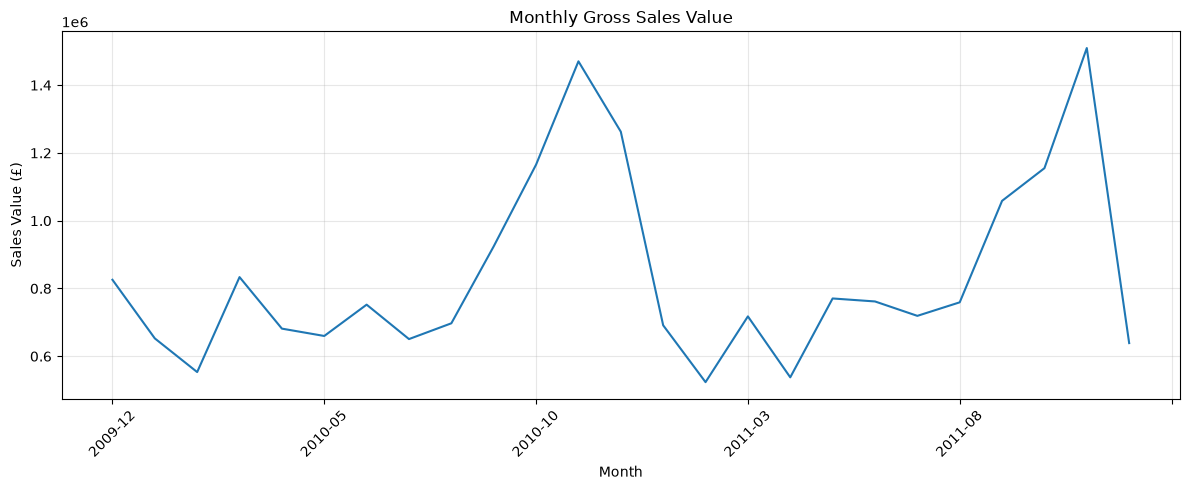

In [10]:
import matplotlib.pyplot as plt

monthly_sales = (
    valid_sales.groupby("year_month")["revenue"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 5))
monthly_sales.plot()

plt.title("Monthly Gross Sales Value")
plt.xlabel("Month")
plt.ylabel("Sales Value (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
output_path = project_root / "data" / "processed"
output_path.mkdir(parents=True, exist_ok=True)

clean.to_csv(
    output_path / "transactions_classified.csv",
    index=False
)

valid_sales.to_csv(
    output_path / "valid_sales.csv",
    index=False
)

quality_report.to_csv(
    output_path / "data_quality_report.csv"
)

print("Files exported successfully!")

Files exported successfully!


In [12]:
print("Dataset shape:", df.shape)
print("\nTransaction classifications:")
print(clean["transaction_status"].value_counts())
print("\nExact duplicates:", clean.duplicated(subset=df.columns.tolist()).sum())
print("\nTop 10 countries:")
print(country_sales)

Dataset shape: (1067371, 10)

Transaction classifications:
transaction_status
Valid Sale      1041670
Cancellation      19494
Review             6207
Name: count, dtype: int64

Exact duplicates: 12133

Top 10 countries:
country
United Kingdom    1.787098e+07
EIRE              6.644318e+05
Netherlands       5.542323e+05
Germany           4.312625e+05
France            3.569446e+05
Australia         1.699681e+05
Spain             1.091785e+05
Switzerland       1.010113e+05
Sweden            9.190372e+04
Denmark           6.986219e+04
Name: revenue, dtype: float64


In [13]:
review_df = clean[
    clean["transaction_status"] == "Review"
].copy()

print("Review records:", len(review_df))

print("\nMissing values:")
print(review_df.isna().sum())

print("\nQuantity statistics:")
print(review_df["quantity"].describe())

print("\nPrice statistics:")
print(review_df["unit_price"].describe())

print("\nSample review records:")
display(review_df[
    [
        "invoice_no",
        "stock_code",
        "description",
        "quantity",
        "unit_price",
        "customer_id",
        "country"
    ]
].head(20))

Review records: 6207

Missing values:
invoice_no               0
stock_code               0
description           4382
quantity                 0
invoice_date             0
unit_price               0
customer_id           6136
country                  0
source_sheet             0
is_cancellation          0
is_valid_sale            0
transaction_status       0
revenue                  0
year                     0
month                    0
year_month               0
day_of_week              0
dtype: int64

Quantity statistics:
count     6207.000000
mean       -51.686966
std        632.123637
min      -9600.000000
25%        -32.000000
50%         -2.000000
75%          3.000000
max      12540.000000
Name: quantity, dtype: float64

Price statistics:
count     6207.000000
mean       -25.564063
std       1028.678307
min     -53594.360000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.000000
Name: unit_price, dtype: float64

Sample review records:


,invoice_no,stock_code,description,quantity,unit_price,customer_id,country
263,489464,21733,85123a mixed,-96,0.0,<NA>,United Kingdom
283,489463,71477,short,-240,0.0,<NA>,United Kingdom
284,489467,85123A,21733 mixed,-192,0.0,<NA>,United Kingdom
470,489521,21646,NaN,-50,0.0,<NA>,United Kingdom
3114,489655,20683,NaN,-44,0.0,<NA>,United Kingdom
3161,489659,21350,NaN,230,0.0,<NA>,United Kingdom
3162,489660,35956,lost,-1043,0.0,<NA>,United Kingdom
3168,489663,35605A,damages,-117,0.0,<NA>,United Kingdom
3731,489781,84292,NaN,17,0.0,<NA>,United Kingdom
4296,489806,18010,NaN,-770,0.0,<NA>,United Kingdom


In [14]:
original_columns = [
    "invoice_no",
    "stock_code",
    "description",
    "quantity",
    "invoice_date",
    "unit_price",
    "customer_id",
    "country",
    "source_sheet"
]

duplicates = clean[
    clean.duplicated(
        subset=original_columns,
        keep=False
    )
].sort_values(
    ["invoice_no", "stock_code"]
)

print("Rows in duplicate groups:", len(duplicates))

print(
    "Duplicate rows beyond first occurrence:",
    clean.duplicated(
        subset=original_columns
    ).sum()
)

display(duplicates[original_columns].head(20))

Rows in duplicate groups: 23430
Duplicate rows beyond first occurrence: 12133


,invoice_no,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,source_sheet
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,Year 2009-2010
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom,Year 2009-2010
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329,United Kingdom,Year 2009-2010
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329,United Kingdom,Year 2009-2010


In [15]:
print("Cancellation records:",
      clean["is_cancellation"].sum())

print(
    "Cancellations with negative quantity:",
    (
        clean["is_cancellation"]
        & (clean["quantity"] < 0)
    ).sum()
)

print(
    "Negative quantities without C invoice:",
    (
        ~clean["is_cancellation"]
        & (clean["quantity"] < 0)
    ).sum()
)

print(
    "Cancellations with positive quantity:",
    (
        clean["is_cancellation"]
        & (clean["quantity"] > 0)
    ).sum()
)

Cancellation records: 19494
Cancellations with negative quantity: 19493
Negative quantities without C invoice: 3457
Cancellations with positive quantity: 1


In [16]:
print(
    "Missing customer IDs in valid sales:",
    valid_sales["customer_id"].isna().sum()
)

print(
    "Known customers:",
    valid_sales["customer_id"].nunique()
)

print(
    "Revenue from unidentified customers:",
    valid_sales.loc[
        valid_sales["customer_id"].isna(),
        "revenue"
    ].sum()
)

Missing customer IDs in valid sales: 236121
Known customers: 5878
Revenue from unidentified customers: 3229165.39


In [17]:
import numpy as np
import pandas as pd

clean["is_cancellation"] = (
    clean["invoice_no"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

conditions = [
    clean["is_cancellation"],
    (clean["quantity"] < 0),
    (clean["unit_price"] < 0),
    (clean["unit_price"] == 0),
    (
        (clean["quantity"] > 0)
        & (clean["unit_price"] > 0)
        & clean["invoice_date"].notna()
        & clean["invoice_no"].notna()
        & clean["stock_code"].notna()
    )
]

choices = [
    "Cancellation",
    "Negative Quantity Adjustment",
    "Negative Price Adjustment",
    "Zero Price Transaction",
    "Valid Sale"
]

clean["transaction_type"] = np.select(
    conditions,
    choices,
    default="Other Review"
)

print(clean["transaction_type"].value_counts())

assert len(clean) == clean["transaction_type"].value_counts().sum()

transaction_type
Valid Sale                      1041670
Cancellation                      19494
Negative Quantity Adjustment       3457
Zero Price Transaction             2745
Negative Price Adjustment             5
Name: count, dtype: int64


In [18]:
original_columns = [
    "invoice_no", "stock_code", "description",
    "quantity", "invoice_date", "unit_price",
    "customer_id", "country", "source_sheet"
]

clean["is_duplicate_extra"] = clean.duplicated(
    subset=original_columns,
    keep="first"
)

sale_mask = clean["transaction_type"] == "Valid Sale"

clean["gross_sales_value"] = np.where(
    sale_mask,
    clean["quantity"] * clean["unit_price"],
    0.0
)

duplicate_sales_value = clean.loc[
    sale_mask & clean["is_duplicate_extra"],
    "gross_sales_value"
].sum()

total_sales_value = clean.loc[
    sale_mask,
    "gross_sales_value"
].sum()

print(f"Gross sales value: £{total_sales_value:,.2f}")
print(f"Duplicate-associated value: £{duplicate_sales_value:,.2f}")

print(
    "Potential percentage impact:",
    round(100 * duplicate_sales_value / total_sales_value, 2)
    if total_sales_value else 0,
    "%"
)

Gross sales value: £20,972,594.57
Duplicate-associated value: £58,703.10
Potential percentage impact: 0.28 %


In [19]:
sales = clean[
    clean["transaction_type"] == "Valid Sale"
].copy()

customer_sales = sales[
    sales["customer_id"].notna()
].copy()

print("All valid sales:", len(sales))
print("Customer-linked sales:", len(customer_sales))
print("Unique customers:", customer_sales["customer_id"].nunique())

print(
    "Customer-linked gross sales: £"
    f"{customer_sales['gross_sales_value'].sum():,.2f}"
)

All valid sales: 1041670
Customer-linked sales: 805549
Unique customers: 5878
Customer-linked gross sales: £17,743,429.18


In [20]:
output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

clean.to_csv(
    output_dir / "transactions_classified_v2.csv",
    index=False
)

sales.to_csv(
    output_dir / "sales_for_analysis.csv",
    index=False
)

customer_sales.to_csv(
    output_dir / "customer_sales_for_rfm.csv",
    index=False
)

print("All three datasets exported successfully.")

All three datasets exported successfully.


In [21]:
print("Transaction type distribution:")
print(clean["transaction_type"].value_counts())

print("\nDuplicate financial impact:")
print(f"£{duplicate_sales_value:,.2f}")

print("\nCustomer-linked sales:")
print(len(customer_sales))

print("\nCustomer-linked gross sales:")
print(f"£{customer_sales['gross_sales_value'].sum():,.2f}")

Transaction type distribution:
transaction_type
Valid Sale                      1041670
Cancellation                      19494
Negative Quantity Adjustment       3457
Zero Price Transaction             2745
Negative Price Adjustment             5
Name: count, dtype: int64

Duplicate financial impact:
£58,703.10

Customer-linked sales:
805549

Customer-linked gross sales:
£17,743,429.18


In [22]:
print("Total gross sales:", round(sales["gross_sales_value"].sum(), 2))

print(
    "Known customer gross sales:",
    round(
        sales.loc[
            sales["customer_id"].notna(),
            "gross_sales_value"
        ].sum(), 2
    )
)

print(
    "Unknown customer gross sales:",
    round(
        sales.loc[
            sales["customer_id"].isna(),
            "gross_sales_value"
        ].sum(), 2
    )
)

assert len(sales) == (
    sales["customer_id"].notna().sum()
    + sales["customer_id"].isna().sum()
)

print("Customer population validation passed!")

Total gross sales: 20972594.57
Known customer gross sales: 17743429.18
Unknown customer gross sales: 3229165.39
Customer population validation passed!


In [23]:
export_columns = [
    "invoice_no",
    "stock_code",
    "description",
    "quantity",
    "invoice_date",
    "unit_price",
    "customer_id",
    "country",
    "source_sheet",
    "is_cancellation",
    "is_valid_sale",
    "transaction_status",
    "revenue",
    "year",
    "month",
    "year_month",
    "day_of_week",
    "transaction_type",
    "is_duplicate_extra",
    "gross_sales_value"
]

db_export = clean[export_columns].copy()

db_export.to_csv(
    output_dir / "transactions_postgresql.csv",
    index=False,
    na_rep=""
)

print("PostgreSQL CSV created:", len(db_export), "rows")

PostgreSQL CSV created: 1067371 rows


In [24]:
from pathlib import Path

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

export_columns = [
    "invoice_no",
    "stock_code",
    "description",
    "quantity",
    "invoice_date",
    "unit_price",
    "customer_id",
    "country",
    "source_sheet",
    "is_cancellation",
    "is_valid_sale",
    "transaction_status",
    "revenue",
    "year",
    "month",
    "year_month",
    "day_of_week",
    "transaction_type",
    "is_duplicate_extra",
    "gross_sales_value"
]

db_export = clean[export_columns].copy()

csv_path = output_dir / "transactions_postgresql.csv"

db_export.to_csv(
    csv_path,
    index=False,
    na_rep=""
)

print("CSV created:", csv_path)
print("Total records:", len(db_export))

CSV created: C:\Users\BHARATH KRISHNA P\Documents\European-Ecommerce-Analytics\data\processed\transactions_postgresql.csv
Total records: 1067371
